# Assignment — K-Means Clustering: Mall Customer Segmentation

## Business context

You are the owner of a supermarket and want to understand your customers' behaviour. You need to identify who could easily become a loyal client of your supermarket (your **target customers**). To do so, you will **group customers by their behaviour** so that the marketing team can plan its strategies accordingly.

## Learning goals

This is your first hands-on work with **unsupervised learning**. By the end of this assignment you will be able to:

- audit and explore a dataset before modelling;
- explain why **standardisation** matters for K-Means (which relies on Euclidean distance);
- choose the number of clusters $k$ with the **elbow method** and the **silhouette score**;
- fit, profile and visualise a K-Means solution;
- evaluate clustering quality **without ground-truth labels** (cardinality, magnitude, stability, sanity checks);
- turn clusters into **actionable business recommendations**.

## The dataset

`Mall_Customers.csv` contains 200 customers described by:

| Column | Meaning |
|---|---|
| `CustomerID` | Unique identifier |
| `Gender` | Male / Female |
| `Age` | Age in years |
| `Annual Income (k$)` | Annual income in thousands of dollars |
| `Spending Score (1-100)` | Index showing how likely a customer is to spend. Higher = higher probability of spending money in the supermarket |

> **Important:** there is **no "correct answer"** in this dataset. Nobody can tell you the right clusters: you must justify your choices with evidence.

> **Deliverable:** complete every `TODO` cell and answer every Markdown `TODO` prompt with clear explanations.

## Assessment checklist

- [ ] Load and audit the data
- [ ] Perform visual EDA (numerical **and** categorical variables) and examine scale/correlation
- [ ] Engineer at least two features
- [ ] Standardise features before K-Means
- [ ] Compare candidate values of $k$ with inertia (elbow) and silhouette score
- [ ] Fit K-Means and print the centroids
- [ ] Visualise clusters (income vs spending score)
- [ ] Evaluate clustering quality: cardinality, magnitude, stability, similar-points check
- [ ] Name each cluster ("type of client") and write marketing recommendations
- [ ] State limitations and possible improvements

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load and inspect the data

Load the dataset and take a first look. `CustomerID` is only an identifier: it carries no behavioural information and must **not** be used as a clustering feature.

In [2]:
df = pd.read_csv("Mall_Customers.csv")

print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# TODO 1: Audit the data
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
print("Duplicated CustomerID:", df["CustomerID"].duplicated().sum())
print("\nGender counts:")
print(df["Gender"].value_counts())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicated rows: 0
Duplicated CustomerID: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**Audit observations:**

- The data is clean: 200 customers, no missing values, no duplicated rows and no duplicated CustomerID.
- Ranges: Age goes from 18 to 70 (mean 38.9), Annual Income from 15 to 137 k$ (mean 60.6) and Spending Score from 1 to 99 (mean 50.2).
- The scales are not the same: income goes up to 137 while age stays below 70, and the standard deviations are also different (26.3 for income, 25.8 for spending, 14.0 for age). Without scaling, income would weigh more in the distances.
- There are 112 women and 88 men.
- `CustomerID` must be excluded because it is just a row number with no behavioural meaning. `Gender` is text, so it cannot be used directly by K-Means.

## 3. Exploratory data analysis (EDA)

EDA helps you understand the geometry that K-Means will "see". Explore distributions, relationships and possible groupings --> remembering that in a real unsupervised task, nobody gives you the groups.

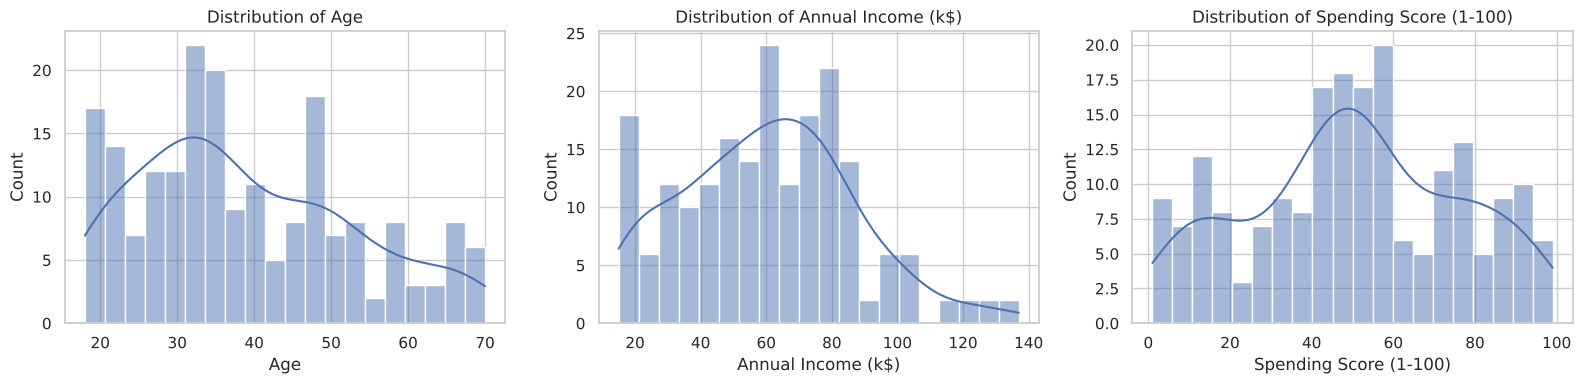

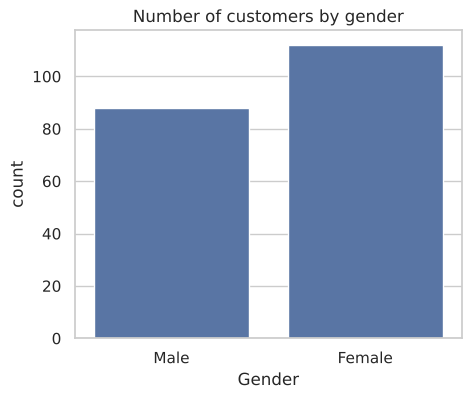

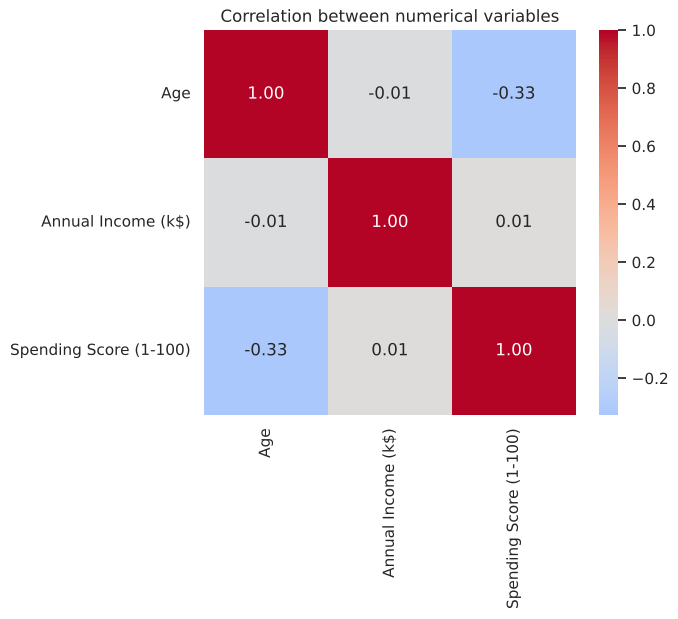

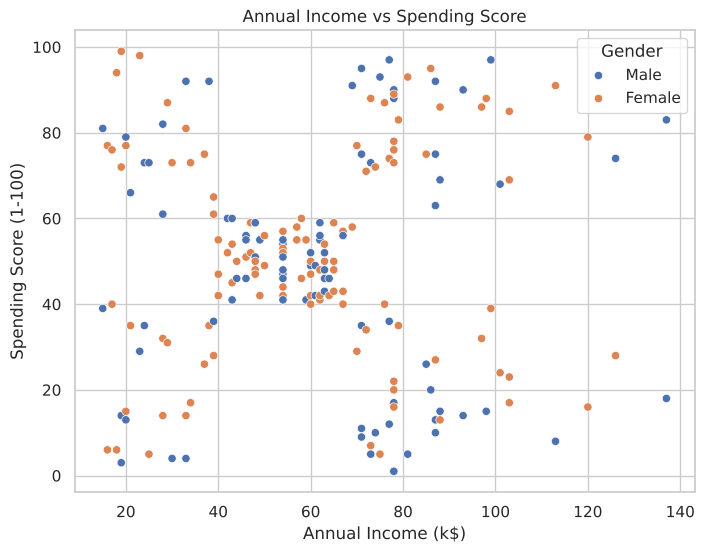

In [4]:
# TODO 2: EDA visualisations
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

# 1) histograms of the numerical variables
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# 2) count plot of Gender
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Gender")
plt.title("Number of customers by gender")
plt.show()

# 3) correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numerical variables")
plt.show()

# 4) Annual Income vs Spending Score (coloured by Gender)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Gender")
plt.title("Annual Income vs Spending Score")
plt.show()

**EDA interpretation:**

- Income and Spending Score are not correlated at all (r = 0.01), and Age and Income neither (r = -0.01). The only noticeable link is between Age and Spending Score (r = -0.33): younger customers tend to have higher spending scores.
- The **Annual Income vs Spending Score** scatter plot clearly shows groups. I count **5 blobs**: one in the middle (average income, average spending) and four in the corners (low/low, low/high, high/low, high/high). Colouring by Gender does not separate anything, men and women are mixed in every group.
- A 2D plot only shows two variables at a time. When more dimensions are used, points that look close in the plot can be far apart on another variable (for example age), and groups that look separated can overlap in the full space. So the plot is a hint, not a proof.

## 4. Feature engineering and preprocessing

K-Means uses **Euclidean distance**, so features on very different scales (e.g. income up to 137 vs. spending score up to 99 vs. age) do not contribute equally unless you standardise them.

### 4.1 Feature engineering

Create **at least two** new features (based only on the columns of the dataset) and define the list `cluster_features` that K-Means will use.

Ideas:

- `spending_to_income_ratio = Spending Score / Annual Income (k$)` → how much a customer spends relative to their means;
- `is_female` = 1 if Gender is Female, 0 otherwise → a numerical version of a categorical variable;
- `income_x_spending = Annual Income × Spending Score` → a combined "purchasing power" proxy;
- `age_group` (e.g. young / adult / senior) using `pd.cut` → useful for **profiling** clusters afterwards (you may or may not use it for clustering, justify your choice).

> **Think about it:** is it a good idea to feed a 0/1 variable such as Gender to K-Means after standardisation? Discuss it in your rationale.

In [5]:
# TODO 3: Feature engineering
df["spending_to_income_ratio"] = df["Spending Score (1-100)"] / df["Annual Income (k$)"]
df["is_female"] = (df["Gender"] == "Female").astype(int)
df["income_x_spending"] = df["Annual Income (k$)"] * df["Spending Score (1-100)"]
df["age_group"] = pd.cut(df["Age"], bins=[17, 30, 50, 70], labels=["young", "adult", "senior"])

new_cols = ["spending_to_income_ratio", "is_female", "income_x_spending"]
print("Missing:", df[new_cols].isna().sum().sum())
print("Infinite:", np.isinf(df[new_cols]).sum().sum())
print(df["age_group"].value_counts())

cluster_features = ["Annual Income (k$)", "Spending Score (1-100)"]
df.head()

Missing: 0
Infinite: 0
age_group
adult     98
young     62
senior    40
Name: count, dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),spending_to_income_ratio,is_female,income_x_spending,age_group
0,1,Male,19,15,39,2.600000,0,585,young
1,2,Male,21,15,81,5.400000,0,1215,young
2,3,Female,20,16,6,0.375000,1,96,young
3,4,Female,23,16,77,4.812500,1,1232,young
4,5,Female,31,17,40,2.352941,1,680,adult


**Feature rationale:**

- `spending_to_income_ratio = Spending Score / Annual Income (k$)`: how much a customer spends compared with what they earn. A high value means someone who spends a lot with a small budget.
- `is_female = 1 if Gender == "Female" else 0`: numerical version of Gender.
- `income_x_spending = Annual Income × Spending Score`: a rough "value" of the customer, high only when both income and spending are high.
- `age_group` (young 18-30 / adult 31-50 / senior 51-70) with `pd.cut`: only for describing the clusters afterwards.

For `cluster_features` I kept only **Annual Income and Spending Score**. These are the two behavioural variables that the business question is about, and the EDA showed clear groups on them. I tested adding Age and the ratio: the silhouette scores were lower (around 0.42 with Age), and the clusters were harder to explain. The other engineered features are used to profile the clusters.

About Gender: after standardisation, a 0/1 variable only takes two values, so it creates a big jump in distance between men and women. K-Means would then tend to split customers by gender instead of by behaviour, and the EDA showed that gender does not separate the groups. So I did not use it for clustering.

### 4.2 Standardisation

In [6]:
# TODO 4: Preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_prepared = preprocessor.fit_transform(df[cluster_features])
scaler = preprocessor.named_steps["scaler"]

print("Shape:", X_prepared.shape)
print("Means:", X_prepared.mean(axis=0).round(3))
print("Std  :", X_prepared.std(axis=0).round(3))

Shape: (200, 2)
Means: [-0. -0.]
Std  : [1. 1.]


**Why scale?** Income has values between 15 and 137, so differences between customers can be around 100, while a 0-1 feature changes by 1 at most. The Euclidean distance would be almost entirely determined by income, and the clusters would just be income bands, ignoring the other feature. Standardisation puts all features on the same scale so they count equally.

## 5. Select the number of clusters

Fit K-Means for $k = 2$ through $k = 10$. Use `n_init=20` and `random_state=RANDOM_STATE` for every run.

- **Inertia** (within-cluster sum of squared distances) always decreases as $k$ increases: look for the **bend ("elbow")**, not for the absolute minimum.
- **Silhouette score** measures how well separated the clusters are (between −1 and 1). Larger is better, but interpretability for the marketing team and stability also matter.

,k,inertia,silhouette
0,2,269.691,0.321
1,3,157.704,0.467
2,4,108.921,0.494
3,5,65.568,0.555
4,6,55.057,0.540
5,7,44.865,0.528
6,8,37.148,0.457
7,9,32.392,0.457
8,10,29.686,0.436


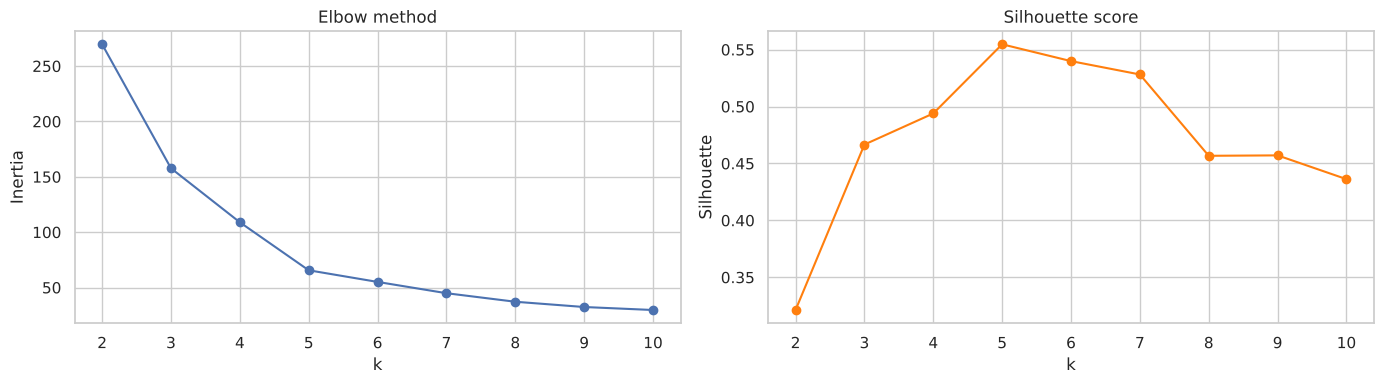

In [7]:
# TODO 5: Inertia and silhouette for k = 2..10
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_prepared)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_prepared, labels))

display(pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="tab:orange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Choice of k:** I chose **k = 5**.

- **Elbow:** inertia drops a lot until k = 5 (from 269.7 at k = 2 to 65.6 at k = 5). After that the decrease is much smaller (55.1 at k = 6, 44.9 at k = 7), so the bend is at k = 5.
- **Silhouette:** the maximum is at k = 5 (0.555). It goes down slowly for k = 6 (0.540) and k = 7 (0.528), then falls to about 0.46 from k = 8.

Both criteria agree, and this also matches the 5 blobs seen in the scatter plot. I did not choose k = 6: the silhouette is slightly lower and the extra cluster mostly splits an existing group, which does not give the marketing team a really new segment. k = 4 has a lower silhouette (0.494) and merges two different groups.

## 6. Fit, profile and visualise the clusters

Fit a final K-Means model with your selected $k$, print the centroids, and describe each cluster with the **original** (non-standardised) variables so that they are interpretable.

In [8]:
# TODO 6: Final model and profiling
best_k = 5
final_kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE)
labels = final_kmeans.fit_predict(X_prepared)

df_clustered = df.copy()
df_clustered["cluster"] = labels

print("Centroids (standardised space):")
print(final_kmeans.cluster_centers_.round(3))

centroids_original = pd.DataFrame(scaler.inverse_transform(final_kmeans.cluster_centers_),
                                  columns=cluster_features)
print("\nCentroids (original units):")
display(centroids_original.round(1))

print("Cluster sizes:")
print(df_clustered["cluster"].value_counts().sort_index())

profile = df_clustered.groupby("cluster").agg(
    size=("CustomerID", "count"),
    age_mean=("Age", "mean"),
    age_median=("Age", "median"),
    income_mean=("Annual Income (k$)", "mean"),
    income_median=("Annual Income (k$)", "median"),
    spending_mean=("Spending Score (1-100)", "mean"),
    spending_median=("Spending Score (1-100)", "median"),
    pct_women=("is_female", "mean"),
    ratio_mean=("spending_to_income_ratio", "mean"),
    income_x_spending_mean=("income_x_spending", "mean"),
)
profile["pct_women"] = profile["pct_women"] * 100
profile.round(2)

Centroids (standardised space):
[[-0.201 -0.026]
 [ 0.992  1.24 ]
 [-1.33   1.132]
 [ 1.055 -1.284]
 [-1.308 -1.137]]

Centroids (original units):


,Annual Income (k$),Spending Score (1-100)
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


Cluster sizes:
cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,size,age_mean,age_median,income_mean,income_median,spending_mean,spending_median,pct_women,ratio_mean,income_x_spending_mean
cluster,,,,,,,,,,
0,81,42.72,46.0,55.30,54.0,49.52,50.0,59.26,0.93,2722.60
1,39,32.69,32.0,86.54,79.0,82.13,83.0,53.85,0.98,7101.41
2,22,25.27,23.5,25.73,24.5,79.36,77.0,59.09,3.37,2033.23
3,35,41.11,42.0,88.20,85.0,17.11,16.0,45.71,0.19,1547.31
4,23,45.22,46.0,26.30,25.0,20.91,17.0,60.87,0.86,564.61


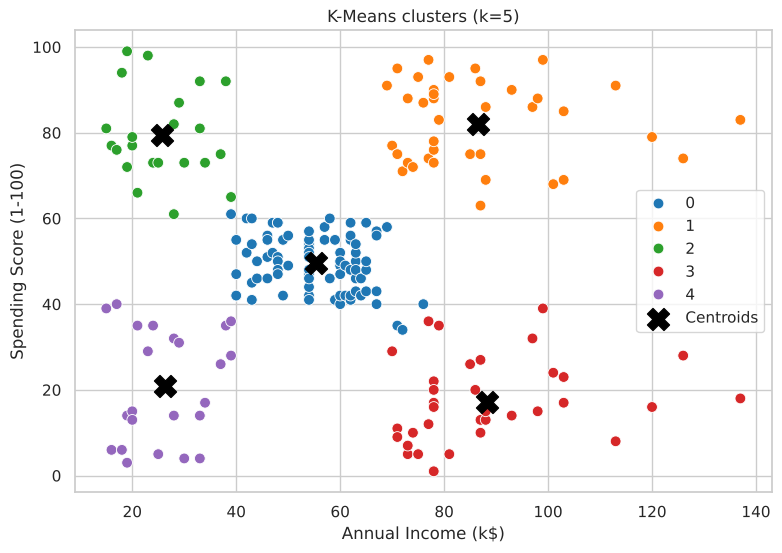

In [9]:
# TODO 7: Plot the clusters
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_clustered, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="cluster", palette="tab10", s=60)
plt.scatter(centroids_original["Annual Income (k$)"], centroids_original["Spending Score (1-100)"],
            c="black", marker="X", s=250, label="Centroids")
plt.title(f"K-Means clusters (k={best_k})")
plt.legend()
plt.show()

**Visual interpretation:** Yes, the five clusters are compact and clearly separated. Each centroid is in the middle of its group: the central cluster (average income and spending) and the four corner groups. The high-income clusters (1 and 3) are a bit more spread out than the others, and there are a few points on the borders between the central cluster and the low-income ones (for example around 40 k$ income and a spending score of 60).

## 7. Evaluate the clustering quality

With no ground-truth labels, quality must be assessed with **internal** criteria and common-sense checks.

- **Cluster cardinality**: number of points in each cluster. Very unbalanced clusters may indicate a poor $k$ (or a genuine small niche).
- **Cluster magnitude**: sum (or mean) of the distances between each point and its cluster centroid. A large magnitude means a "loose" cluster.
- **Stability**: does K-Means find (almost) the same clusters when initialised differently?
- **Sanity check**: are very similar customers assigned to the same cluster?

If the values look poor, go back to Section 5/6 and try another $k$.

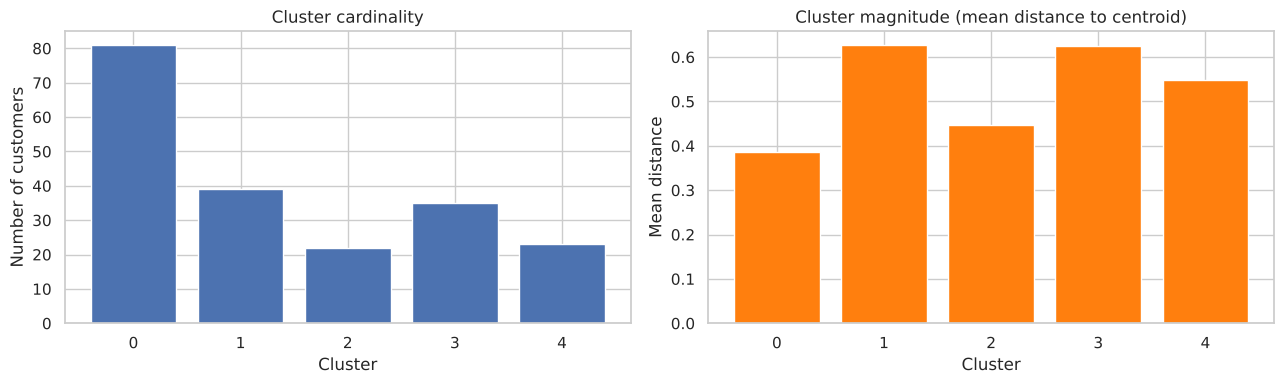

,cardinality,magnitude
cluster,,
0,81,0.387
1,39,0.627
2,22,0.447
3,35,0.625
4,23,0.549


In [10]:
# TODO 8a: Cardinality and magnitude
distances = final_kmeans.transform(X_prepared)
df_clustered["dist_to_centroid"] = distances[np.arange(len(labels)), labels]

cardinality = df_clustered["cluster"].value_counts().sort_index()
magnitude = df_clustered.groupby("cluster")["dist_to_centroid"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(cardinality.index, cardinality.values)
axes[0].set_title("Cluster cardinality")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of customers")
axes[1].bar(magnitude.index, magnitude.values, color="tab:orange")
axes[1].set_title("Cluster magnitude (mean distance to centroid)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Mean distance")
plt.tight_layout()
plt.show()

pd.DataFrame({"cardinality": cardinality, "magnitude": magnitude.round(3)})

In [11]:
# TODO 8b: Stability check
aris = []
for seed in range(10):
    km = KMeans(n_clusters=best_k, n_init=20, random_state=seed)
    aris.append(adjusted_rand_score(labels, km.fit_predict(X_prepared)))

print("ARI per run:", np.round(aris, 3))
print(f"min = {min(aris):.3f}, mean = {np.mean(aris):.3f}, max = {max(aris):.3f}")

ARI per run: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
min = 1.000, mean = 1.000, max = 1.000


In [12]:
# TODO 8c: Similar-points check
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=10).fit(X_prepared)

# one customer in the middle of a group
_, idx = nn.kneighbors(X_prepared[[0]])
print("Neighbours of customer 1:")
display(df_clustered.iloc[idx[0]][["CustomerID", "Annual Income (k$)", "Spending Score (1-100)", "cluster"]])

# one customer close to a border between groups
_, idx = nn.kneighbors(X_prepared[[43]])
print("Neighbours of customer 44:")
display(df_clustered.iloc[idx[0]][["CustomerID", "Annual Income (k$)", "Spending Score (1-100)", "cluster"]])

Neighbours of customer 1:


,CustomerID,Annual Income (k$),Spending Score (1-100),cluster
0,1,15,39,4
4,5,17,40,4
16,17,21,35,4
20,21,24,35,4
18,19,23,29,4
26,27,28,32,4
28,29,29,31,4
40,41,38,35,4
42,43,39,36,4
12,13,20,15,4


Neighbours of customer 44:


,CustomerID,Annual Income (k$),Spending Score (1-100),cluster
43,44,39,61,0
51,52,42,60,0
45,46,39,65,2
53,54,43,60,0
46,47,40,55,0
52,53,43,54,0
63,64,47,59,0
60,61,46,56,0
68,69,48,59,0
65,66,48,59,0


**Quality assessment:**

- **Cardinality:** the sizes are 81, 39, 35, 23 and 22. The central cluster is the largest, which is normal since most customers are average. The smaller clusters are still big enough (22+ customers) to be real segments and not noise.
- **Magnitude:** the central cluster is the most compact (mean distance 0.39). The two high-income clusters are the loosest (0.63 and 0.63) because high incomes are more spread out, but they stay reasonable.
- **Stability:** all 10 runs with different random states gave exactly the same partition (ARI = 1.000 for min, mean and max), so the solution does not depend on initialisation.
- **Similar points:** customer 1 and its 9 nearest neighbours are all in cluster 4. For customer 44, which is close to a border, 9 of the 10 neighbours are in cluster 0 and one (customer 46, income 39, score 65) is in cluster 2. This is a border point between two groups, not a problem with k.

I keep k = 5: the results are stable and the clusters are easy to interpret.

## 8. Recommendations for the marketing team

Create a new column called `type of client` in your dataset and give each cluster an **interesting, business-friendly name** based on the data you explored.

For instance:

- a cluster of clients with **high income and high spending score** could be called *"Luxury shoppers"*;
- a cluster of **young, low-income but high-spending** clients could be called *"Impulsive shoppers"*.

You must explore the data of each cluster (profile table, plots) to justify such names.

In [13]:
# TODO 9a: Name the clusters
cluster_names = {
    0: "Average shoppers",
    1: "Luxury shoppers",
    2: "Impulsive shoppers",
    3: "Wealthy savers",
    4: "Budget-conscious shoppers",
}
df_clustered["type of client"] = df_clustered["cluster"].map(cluster_names)
df_clustered.groupby("type of client")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)

,Age,Annual Income (k$),Spending Score (1-100)
type of client,,,
Average shoppers,42.7,55.3,49.5
Budget-conscious shoppers,45.2,26.3,20.9
Impulsive shoppers,25.3,25.7,79.4
Luxury shoppers,32.7,86.5,82.1
Wealthy savers,41.1,88.2,17.1


In [14]:
# TODO 9b: 5 examples per cluster
cols = ["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)", "cluster", "type of client"]
for c in sorted(cluster_names):
    print(f"Cluster {c} - {cluster_names[c]}")
    display(df_clustered[df_clustered["cluster"] == c][cols].head(5))

Cluster 0 - Average shoppers


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,type of client
43,44,Female,31,39,61,0,Average shoppers
46,47,Female,50,40,55,0,Average shoppers
47,48,Female,27,40,47,0,Average shoppers
48,49,Female,29,40,42,0,Average shoppers
49,50,Female,31,40,42,0,Average shoppers


Cluster 1 - Luxury shoppers


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,type of client
123,124,Male,39,69,91,1,Luxury shoppers
125,126,Female,31,70,77,1,Luxury shoppers
127,128,Male,40,71,95,1,Luxury shoppers
129,130,Male,38,71,75,1,Luxury shoppers
131,132,Male,39,71,75,1,Luxury shoppers


Cluster 2 - Impulsive shoppers


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,type of client
1,2,Male,21,15,81,2,Impulsive shoppers
3,4,Female,23,16,77,2,Impulsive shoppers
5,6,Female,22,17,76,2,Impulsive shoppers
7,8,Female,23,18,94,2,Impulsive shoppers
9,10,Female,30,19,72,2,Impulsive shoppers


Cluster 3 - Wealthy savers


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,type of client
124,125,Female,23,70,29,3,Wealthy savers
128,129,Male,59,71,11,3,Wealthy savers
130,131,Male,47,71,9,3,Wealthy savers
134,135,Male,20,73,5,3,Wealthy savers
136,137,Female,44,73,7,3,Wealthy savers


Cluster 4 - Budget-conscious shoppers


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,type of client
0,1,Male,19,15,39,4,Budget-conscious shoppers
2,3,Female,20,16,6,4,Budget-conscious shoppers
4,5,Female,31,17,40,4,Budget-conscious shoppers
6,7,Female,35,18,6,4,Budget-conscious shoppers
8,9,Male,64,19,3,4,Budget-conscious shoppers


**Marketing recommendations:**

**Luxury shoppers (cluster 1, 39 customers)**
1. High income (~87 k$) and high spending score (~82), average age around 33.
2. Yes, the main target customers: they earn a lot and already spend a lot.
3. Loyalty programme with premium rewards (exclusive offers, early access to new products).

**Impulsive shoppers (cluster 2, 22 customers)**
1. Young (~25 years), low income (~26 k$) but very high spending score (~79).
2. Yes, they already like to spend, but their budget is limited, so loyalty depends on prices.
3. Student/young discounts and a points card, promoted on social media.

**Average shoppers (cluster 0, 81 customers)**
1. The largest group: middle income (~55 k$), medium spending (~50), average age around 43.
2. Partly: they are regular customers who could spend more.
3. Weekly promotions and bundle offers (e.g. family packs) to increase the basket.

**Wealthy savers (cluster 3, 35 customers)**
1. High income (~88 k$) but low spending score (~17), around 41 years old.
2. Not yet, but they have the most potential: they have the money but do not spend it here.
3. Awareness campaign on product quality and services (organic, premium range, home delivery) to attract them.

**Budget-conscious shoppers (cluster 4, 23 customers)**
1. Low income (~26 k$) and low spending (~21), the oldest group (~45 years).
2. No, they are not a priority target.
3. Low-cost actions only: discount coupons on basic products.

**Limitations and possible improvements:** the dataset is small (200 customers) and only has 4 variables, so the segments are simple. The Spending Score is an index whose calculation we do not know. K-Means also assumes round clusters of similar size. With more data (purchase history, visit frequency), we could add more behaviour features and try other methods such as hierarchical clustering or DBSCAN.